# Escalado
Conjunto de datos: iris (incluido en sklearn)
Este conjunto de datos es compacto y perfecto para demostrar técnicas de escalado.

In [1]:
# Importar librerías necesarias
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Cargar el conjunto de datos
iris = load_iris(as_frame=True)
data = iris.data

In [3]:
# Visualizar las estadísticas iniciales
print("Estadísticas iniciales:")
data.describe()

Estadísticas iniciales:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [4]:
# Aplicar MinMaxScaler
minmax_scaler = MinMaxScaler()
data_minmax = pd.DataFrame(minmax_scaler.fit_transform(data), columns=data.columns)

In [5]:
# Aplicar StandardScaler
standard_scaler = StandardScaler()
data_standard = pd.DataFrame(standard_scaler.fit_transform(data), columns=data.columns)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre las estadísticas originales y las del escalado MinMax?


In [6]:
print("Originales:")
print(data.describe().loc[['mean','std','min','max']])
print("\nMinMax:")
print(data_minmax.describe().loc[['mean','std','min','max']])

Originales:
      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
mean           5.843333          3.057333           3.758000          1.199333
std            0.828066          0.435866           1.765298          0.762238
min            4.300000          2.000000           1.000000          0.100000
max            7.900000          4.400000           6.900000          2.500000

MinMax:
      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
mean           0.428704          0.440556           0.467458          0.458056
std            0.230018          0.181611           0.299203          0.317599
min            0.000000          0.000000           0.000000          0.000000
max            1.000000          1.000000           1.000000          1.000000


**Respuesta:** en los datos originales cada variable tiene su propio rango (por ejemplo, sepal length va de 4.3 a 7.9 y petal width de 0.1 a 2.5). Con MinMax todas quedan entre 0 y 1: el mínimo pasa a 0 y el máximo a 1. La forma de la distribución no cambia, solo la escala; las medias y desviaciones se vuelven comparables entre variables.

### 2. Crea una gráfica de la distribución de la variable 'sepal length (cm)' antes y después del escalado.

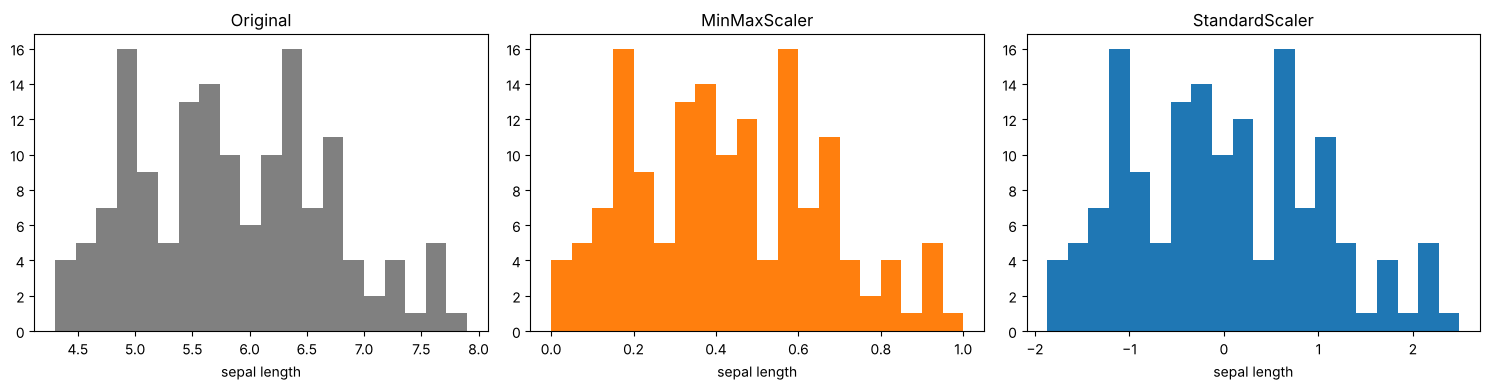

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(data['sepal length (cm)'], bins=20, color='gray'); axes[0].set_title('Original')
axes[1].hist(data_minmax['sepal length (cm)'], bins=20, color='tab:orange'); axes[1].set_title('MinMaxScaler')
axes[2].hist(data_standard['sepal length (cm)'], bins=20, color='tab:blue'); axes[2].set_title('StandardScaler')
for ax in axes: ax.set_xlabel('sepal length')
plt.tight_layout(); plt.show()

**Respuesta:** las tres distribuciones tienen exactamente la misma forma; solo cambia el eje x (cm, rango 0-1 y desviaciones estándar respecto a la media).

### 3. Crea una gráfica de dispersión entre 'sepal length (cm)' y 'sepal width (cm)' con los datos escalados por StandardScaler.

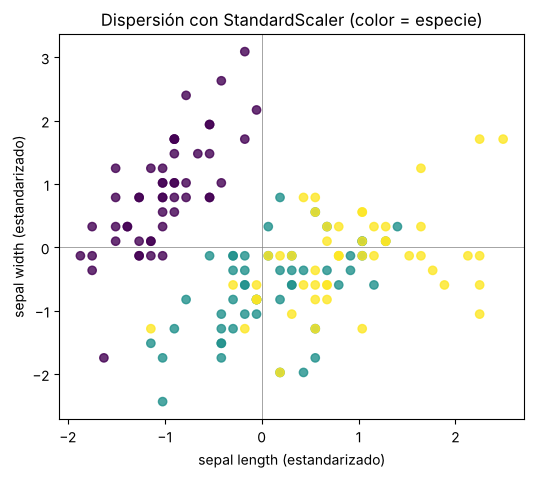

In [8]:
plt.figure(figsize=(6, 5))
plt.scatter(data_standard['sepal length (cm)'], data_standard['sepal width (cm)'],
            c=iris.target, cmap='viridis', alpha=0.8)
plt.axhline(0, color='gray', lw=0.5); plt.axvline(0, color='gray', lw=0.5)
plt.xlabel('sepal length (estandarizado)'); plt.ylabel('sepal width (estandarizado)')
plt.title('Dispersión con StandardScaler (color = especie)')
plt.show()

**Respuesta:** ambas variables quedan centradas en 0 con desviación 1, así que pueden compararse en la misma escala. La setosa se separa claramente (sépalos cortos y anchos).

### 4. ¿Qué técnica de escalado crees que es más adecuada para este conjunto de datos? ¿Por qué?

In [9]:
print("Asimetría (skew) de cada variable:")
print(data.skew())
print("\nValores atípicos por variable (regla 1.5*IQR):")
q1, q3 = data.quantile(0.25), data.quantile(0.75); iqr = q3 - q1
print(((data < q1 - 1.5*iqr) | (data > q3 + 1.5*iqr)).sum())

Asimetría (skew) de cada variable:
sepal length (cm)    0.314911
sepal width (cm)     0.318966
petal length (cm)   -0.274884
petal width (cm)    -0.102967
dtype: float64

Valores atípicos por variable (regla 1.5*IQR):
sepal length (cm)    0
sepal width (cm)     4
petal length (cm)    0
petal width (cm)     0
dtype: int64


**Respuesta:** para iris recomiendo **StandardScaler**. Las variables tienen distribuciones razonablemente simétricas y casi no hay atípicos (solo unos pocos en sepal width), y muchos modelos que se usan con iris (regresión logística, SVM, PCA, KNN) funcionan mejor con datos centrados en 0 y varianza 1. MinMax también sería válido, pero es más sensible a atípicos porque depende del mínimo y máximo exactos; conviene más cuando un algoritmo exige un rango acotado (por ejemplo, redes neuronales o imágenes).